# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1024**2          # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)          # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512       # one ray per (x, z) pixel x 512 steps along y
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

1. **Geometric distortion (squashed anatomy):** the 512 x 512 x 300 grid is 256 x 256 x 300 mm, but pixel for pixel the
   z axis is twice as coarse as x and y (1.0 mm vs 0.5 mm). If the software treats voxels as cubes, coronal and
   sagittal slices are drawn with the z axis compressed by half (heads look flattened, a round lesion looks like a
   flat ellipse). The fix is to display with an aspect ratio of dz/dx = 2 (as `aspect=ASPECT` does in Task 2), or to resample to isotropic voxels.
2. **Wrong measurements:** distances, areas and volumes computed by counting voxels would be wrong. Each voxel is 0.25 mm^3, not
   1 mm^3 or 0.125 mm^3, and a length measured in z-steps would be underestimated by a factor of 2 compared with the same count in x or y,
   so tumour size and lesion-to-structure distances would be misreported. The coronal/sagittal views also look blockier
   along z (stair-stepping), because z has half the resolution of the in-plane directions.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 candidate component(s); lesion = 431 voxels, centroid (z, y, x) = (28, 40, 41)


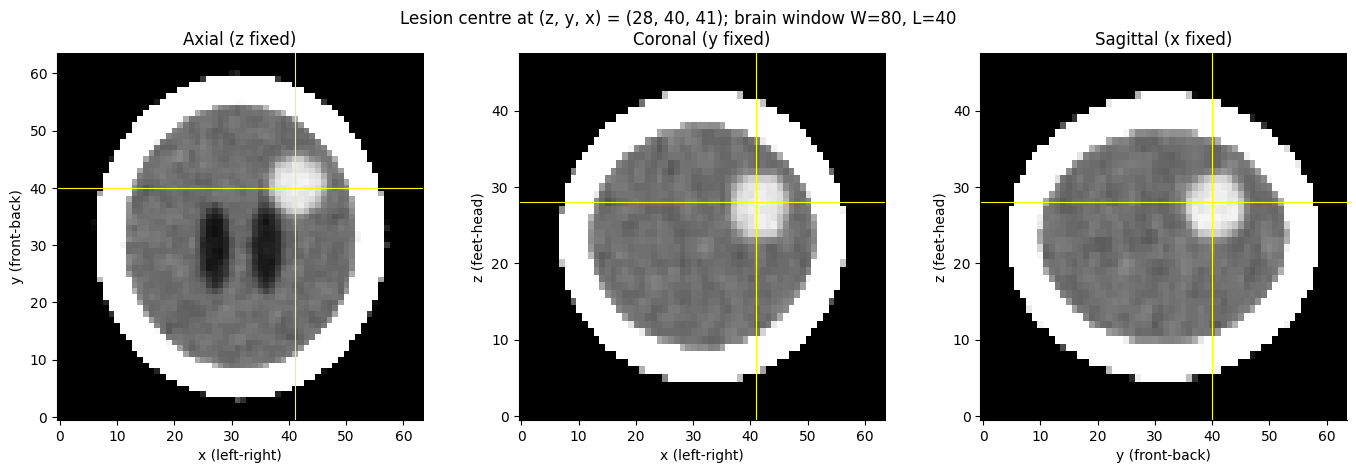

Distance from ground-truth centroid [27.5 40.5 41.5]: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside_eroded = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside_eroded

# TODO 2
lab, n = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lab, range(1, n + 1))
lesion = lab == (np.argmax(sizes) + 1)
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"{n} candidate component(s); lesion = {lesion.sum()} voxels, centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [
    ("Axial (z fixed)",    vol[cz, :, :],  1.0,    (cx, cy), "x (left-right)",  "y (front-back)"),
    ("Coronal (y fixed)",  vol[:, cy, :],  ASPECT, (cx, cz), "x (left-right)",  "z (feet-head)"),
    ("Sagittal (x fixed)", vol[:, :, cx],  ASPECT, (cy, cz), "y (front-back)",  "z (feet-head)"),
]
for ax, (title, sl, asp, (px, py), xl, yl) in zip(axes, views):
    ax.imshow(window(sl, 80, 40), cmap="gray", origin="lower", aspect=asp, vmin=0, vmax=1)
    ax.axvline(px, color="yellow", lw=0.8); ax.axhline(py, color="yellow", lw=0.8)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)
fig.suptitle(f"Lesion centre at (z, y, x) = ({cz}, {cy}, {cx}); brain window W=80, L=40")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
true_c = np.array(ndimage.center_of_mass(labels == 5))
err_mm = np.linalg.norm((np.array([cz, cy, cx]) - true_c) * np.array(SPACING))
print(f"Distance from ground-truth centroid {np.round(true_c, 1)}: {err_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

At every boundary a voxel covers both tissues, so its HU is a weighted average of them (the **partial-volume effect**).
Under the skull, voxels between bone (about 700 HU) and brain (about 20-40 HU) and between scalp/air and bone take every
intermediate value on the way, including values inside the 55-90 HU lesion window. They form a thin shell of "false tumour" voxels that
has the same intensity as real tumour. This is the **overlapping intensity ranges** problem from Slide 28: intensity alone cannot
separate "tumour" from "an edge between two other materials", so a threshold on HU alone picks up both.

Eroding the interior-of-skull mask 3 times removes the layer of voxels next to the bone, where the partial-volume
shell lives, so only the true interior remains. The largest connected component then picks the real lesion, which is a
compact blob, rather than the thin shell fragments.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_HU,voxels,volume_mL,dice
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


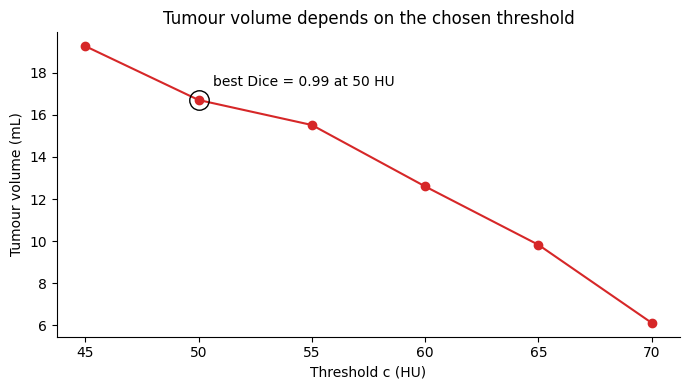

Report to the surgeon: 6.1 - 19.3 mL (best-matching threshold 50 HU gives 16.7 mL)


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    lab_c, _ = ndimage.label(vol > c)
    region = lab_c == lab_c[cz, cy, cx]               # connected component containing the lesion centre
    n_vox = int(region.sum())
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold_HU": c, "voxels": n_vox, "volume_mL": n_vox * VOXEL_MM3 / 1000, "dice": round(float(dice), 3)})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_HU, table.volume_mL, "o-", color="tab:red")
best = table.loc[table.dice.idxmax()]
ax.plot(best.threshold_HU, best.volume_mL, "o", ms=14, mfc="none", mec="k")
ax.annotate(f"best Dice = {best.dice:.2f} at {best.threshold_HU:.0f} HU", (best.threshold_HU, best.volume_mL),
            textcoords="offset points", xytext=(10, 10))
ax.set_xlabel("Threshold c (HU)"); ax.set_ylabel("Tumour volume (mL)")
ax.set_title("Tumour volume depends on the chosen threshold")
plt.tight_layout(); plt.show()

# TODO 4
vmin, vmax = table.volume_mL.min(), table.volume_mL.max()
print(f"Report to the surgeon: {vmin:.1f} - {vmax:.1f} mL (best-matching threshold {best.threshold_HU:.0f} HU gives {best.volume_mL:.1f} mL)")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

**Choosing c:** without labels I would pick c from the data itself: look at the intensity histogram (or a profile across the lesion edge) and
set c at the **midpoint between the two materials**, the half-maximum rule. Brain is about 36 HU and tumour about 68 HU, so
c is about 52 HU. This is exactly where the ground-truth Dice peaks (50 HU, Dice 0.99), and it is the threshold where a
partial-volume voxel (an average of the two tissues) is classed as 50/50. Above it we start eroding real tumour and below it we begin absorbing
brain. I would justify it to the board as "half way between the two tissue intensities", then confirm by eye that the contour sits on the visible edge.

**Showing uncertainty:** I would never give one number. I would (1) report the volume as a **range** from a threshold sweep (the
table shows 15.5-19.3 mL for c = 45-55 HU, but 6 mL at c = 70, which cuts into the tumour); (2) overlay **several contours (e.g. 45, 55, 65 HU) on the MPR slices** so the
surgeon sees how far the boundary moves; and (3) show the volume-vs-threshold curve with the plausible band shaded. The steeper the curve,
the less the surgeon should trust any single value.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

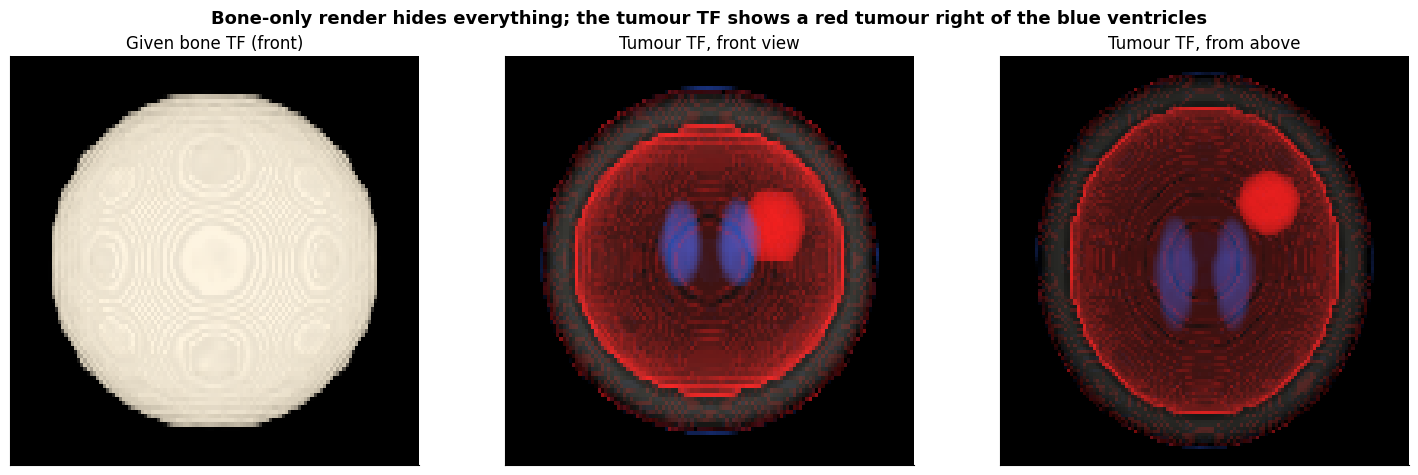

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function  (HU, (r, g, b), alpha-per-sample)
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0), (0, (0, 0, 0), 0.0),                      # air / fat: invisible
    (3, (0.2, 0.4, 1.0), 0.0), (5, (0.2, 0.4, 1.0), 0.02),             # CSF (5-23 HU): blue, faint but it adds up over a thick ventricle
    (12, (0.2, 0.4, 1.0), 0.04), (22, (0.2, 0.4, 1.0), 0.02), (26, (0.2, 0.4, 1.0), 0.0),
    (48, (0, 0, 0), 0.0),                                              # normal brain (about 36 HU): fully transparent (alpha 0 from 26 to 48 HU)
    (52, (1.0, 0.1, 0.1), 0.10), (80, (1.0, 0.1, 0.1), 0.12), (95, (1.0, 0.1, 0.1), 0.0),   # tumour (52-77 HU): red
    (300, (0.9, 0.9, 0.8), 0.0), (400, (0.9, 0.9, 0.8), 0.004), (1500, (1, 1, 1), 0.008),   # bone: alpha <= 0.01, context only
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
for ax, (tf, axis, title) in zip(axes, [(bone_tf, 1, "Given bone TF (front)"),
                                        (tumour_tf, 1, "Tumour TF, front view"),
                                        (tumour_tf, 0, "Tumour TF, from above")]):
    Cimg, Aimg = render(vol, tf, axis=axis)
    ax.imshow(np.clip(Cimg, 0, 1), origin="lower", aspect=(ASPECT if axis == 1 else 1.0))   # z on screen axis -> use ASPECT
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

# TODO 4: suptitle
fig.suptitle("Bone-only render hides everything; the tumour TF shows a red tumour right of the blue ventricles", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

**Cause:** the **partial-volume / overlapping intensity ranges** challenge of Slide 28 (with the accumulation along the ray). A transfer function
maps *intensity only*, so any voxel with 52-80 HU is coloured red. The thin transition layer between brain (about 36 HU) and the skull
(about 700 HU) passes through that range, because each voxel there averages the two tissues. So a shell of "false tumour" appears inside the skull, and along
a ray through its edge the faint opacity of many samples accumulates into a visible red rim.

**Fix:** **segment first and render only the segmented region** (use the region-grown lesion mask from Tasks 2-3 as a mask,
or clip away the shell), so only voxels that are connected to the lesion get colour (Slides 31-32). A transfer function alone
cannot do this because the rim voxels and the real tumour voxels have the **same HU**. T(s) sees only the value, not *where* the voxel is
or what it is connected to, so no choice of colour/opacity curve can keep one set and drop the other.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

**Note to the tumour board:** The lesion sits in the right half of the image and the back half of the brain, slightly above the
mid-height of the head, just beside the two ventricles (about 3 mm from the centre found by the automated search). Its volume is
**about 15.5-19.3 mL** for reasonable thresholds (45-55 HU, best estimate about 16.7 mL at 50 HU), and it falls sharply to around 6 mL if the threshold is too strict, so the
number should be read as a range, not an exact figure. I recommend opening the meeting with the **three-plane slice view (MPR) with the segmentation outline overlaid**: slicing exposes the
internal structure that the 3-D render hides by occlusion, and the segmentation turns the picture into a measurement the surgeon can check on the
anatomy at several thresholds. The 3-D render is good for showing the tumour's relation to the ventricles, but its limitation is that its look depends on the
transfer function. Voxels with the same HU (tumour versus partial-volume shell) cannot be told apart, which produces a false red rim, and it cannot give volumes.